# Permeabilidade relativa — modelo simples de Corey

Curvas sobrepostas de água/salmoura ($k_{rw}$), gás ($k_{rg}$) e óleo ($k_{ro}$), com os parâmetros da tabela fornecida.

| Fase | $k_{ri}^{0}$ | $S_{ir}$ | $\epsilon_i$ |
|---|---:|---:|---:|
| Água / salmoura | 0.365 | 0.36 | 2.7 |
| Óleo | 0.574 | 0.16 | 3.0 |
| Gás | 0.278 | 0.00 | 6.89 |

Usamos a mesma normalização de `models/relativePermeabilityModels.py`:

$$S_{ei}=\operatorname{clip}\left(\frac{S_i-S_{ir}}{1-S_{wr}-S_{or}-S_{gr}},\,0,\,1\right),
\qquad k_{ri}=k_{ri}^{0}S_{ei}^{\epsilon_i}.$$

O denominador é $1-0.36-0.16-0.00=0.48$. A curva é zero abaixo da saturação residual e fica limitada ao valor de referência acima de $S_{ir}+0.48$; esse último trecho é uma extensão para visualização.

**Os dois gráficos usam $S_w$ no eixo horizontal**, com saturações complementares calculadas pelo balanço $S_w+S_g+S_o=1$:

- Água–gás: óleo na saturação residual, $S_o=S_{or}=0.16$, portanto $S_g=1-S_w-S_{or}$.
- Água–óleo: gás na saturação residual, $S_g=S_{gr}=0$, portanto $S_o=1-S_w-S_{gr}$.

Cada gráfico cobre o intervalo físico $S_{wr}\leq S_w\leq S_{wr}+0.48$. Assim, $k_{rw}$ cresce e a permeabilidade da fase complementar diminui com $S_w$.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Parâmetros transcritos da tabela: kr0, saturação residual e expoente.
parametros = {
    "agua": {"kr0": 0.365, "Sr": 0.36, "expoente": 2.7},
    "gas":  {"kr0": 0.278, "Sr": 0.00, "expoente": 6.89},
    "oleo": {"kr0": 0.574, "Sr": 0.16, "expoente": 3.0},
}

saturacao_movel = 1.0 - sum(p["Sr"] for p in parametros.values())
if saturacao_movel <= 0:
    raise ValueError("A soma das saturações residuais deve ser menor que 1.")


def corey(S, kr0, Sr, expoente):
    """Permeabilidade relativa de Corey com saturação efetiva limitada a [0, 1]."""
    Se = np.clip((np.asarray(S) - Sr) / saturacao_movel, 0.0, 1.0)
    return kr0 * Se**expoente


Sw = np.linspace(parametros["agua"]["Sr"], parametros["agua"]["Sr"] + saturacao_movel, 1001)
Sg = 1.0 - Sw - parametros["oleo"]["Sr"]
So = 1.0 - Sw - parametros["gas"]["Sr"]
krw = corey(Sw, **parametros["agua"])
krg = corey(Sg, **parametros["gas"])
kro = corey(So, **parametros["oleo"])


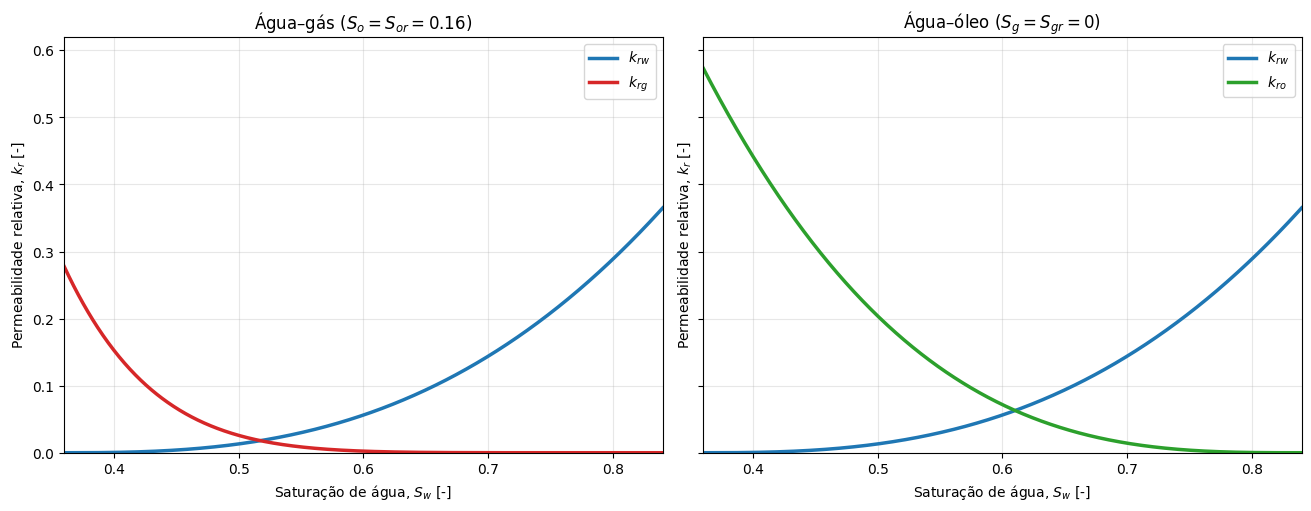

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True, sharex=True, sharey=True)

for ax in axes:
    ax.plot(Sw, krw, color="tab:blue", linewidth=2.5, label=r"$k_{rw}$")
    ax.set_xlabel(r"Saturação de água, $S_w$ [-]")
    ax.set_ylabel(r"Permeabilidade relativa, $k_r$ [-]")
    ax.set_xlim(Sw[0], Sw[-1])
    ax.set_ylim(0, 0.62)
    ax.grid(True, alpha=0.3)

axes[0].plot(Sw, krg, color="tab:red", linewidth=2.5, label=r"$k_{rg}$")
axes[0].set_title(r"Água–gás ($S_o=S_{or}=0.16$)")
axes[1].plot(Sw, kro, color="tab:green", linewidth=2.5, label=r"$k_{ro}$")
axes[1].set_title(r"Água–óleo ($S_g=S_{gr}=0$)")
for ax in axes:
    ax.legend()
plt.show()
